# 01 — Exploratory Data Analysis: WM-811K Wafer Maps

**Goal:** understand the labelled wafer maps well enough to make the key modelling decisions
(metric, train/test split strategy, feature representation).

Input: `data/labelled.pkl`, produced by `python src/prepare_data.py` from the raw `LSWMD.pkl`.

Each wafer map is a 2D array: **0** = no die (outside the wafer), **1** = good die, **2** = defective die.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import ListedColormap

sns.set_theme(style="whitegrid")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

WAFER_CMAP = ListedColormap(["white", "#9ecae1", "#d62728"])  # off-wafer, good, defect
CLASS_ORDER = ["none", "Edge-Ring", "Edge-Loc", "Center", "Loc",
               "Scratch", "Random", "Donut", "Near-full"]
DEFECT_ORDER = CLASS_ORDER[1:]

def savefig(name):
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

In [4]:
df = pd.read_pickle(ROOT / "data" / "labelled.pkl")
df["is_defect"] = df["failureType"] != "none"
df["n_die"] = df["waferMap"].apply(lambda m: int((m > 0).sum()))
df["pct_bad"] = df["waferMap"].apply(lambda m: (m == 2).sum() / max((m > 0).sum(), 1))
print(f"{len(df):,} labelled wafers | {df['lotName'].nunique():,} lots | {df.shape[1]} columns")
df.drop(columns="waferMap").head()

172,950 labelled wafers | 10,762 lots | 11 columns


,dieSize,lotName,waferIndex,trainTestLabel,failureType,n_rows,n_cols,is_defect,n_die,pct_bad
0,1683.0,lot1,1,Training,none,45,48,False,1683,0.052288
1,1683.0,lot1,2,Training,none,45,48,False,1683,0.051099
2,1683.0,lot1,3,Training,none,45,48,False,1683,0.039216
3,1683.0,lot1,4,Training,none,45,48,False,1683,0.061794
4,1683.0,lot1,5,Training,none,45,48,False,1683,0.042187


## Dataset overview

- Source: WM-811K (Wu et al., 2015, *IEEE Trans. Semiconductor Manufacturing*), via Kaggle.
- Raw file: 811,457 wafers from 46,293 lots; only **172,950 (21%) are labelled** — we model those.
- No timestamps → no time period can be stated, and time-based drift cannot be studied.

In [3]:
df.drop(columns="waferMap").describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
dieSize,172950.0,NaN,NaN,NaN,1042.232374,1032.572449,3.0,533.0,776.0,1250.0,22372.0
lotName,172950,10762,lot1,25,NaN,NaN,NaN,NaN,NaN,NaN,NaN
waferIndex,172950.0,NaN,NaN,NaN,13.00418,7.212674,1.0,7.0,13.0,19.0,25.0
trainTestLabel,172950,2,Test,118595,NaN,NaN,NaN,NaN,NaN,NaN,NaN
failureType,172950,9,none,147431,NaN,NaN,NaN,NaN,NaN,NaN,NaN
n_rows,172950.0,NaN,NaN,NaN,35.232807,11.096015,15.0,27.0,33.0,41.0,212.0
n_cols,172950.0,NaN,NaN,NaN,34.822128,11.876781,3.0,27.0,33.0,40.0,204.0
is_defect,172950,2,False,147431,NaN,NaN,NaN,NaN,NaN,NaN,NaN
n_die,172950.0,NaN,NaN,NaN,1042.232374,1032.572449,3.0,533.0,776.0,1250.0,22372.0
pct_bad,172950.0,NaN,NaN,NaN,0.117627,0.073514,0.0,0.069257,0.10567,0.151046,1.0


## Insight 1 — Severe class imbalance

,count,share_%
failureType,,
none,147431,85.24
Edge-Ring,9680,5.60
Edge-Loc,5189,3.00
Center,4294,2.48
Loc,3593,2.08
Scratch,1193,0.69
Random,866,0.50
Donut,555,0.32
Near-full,149,0.09


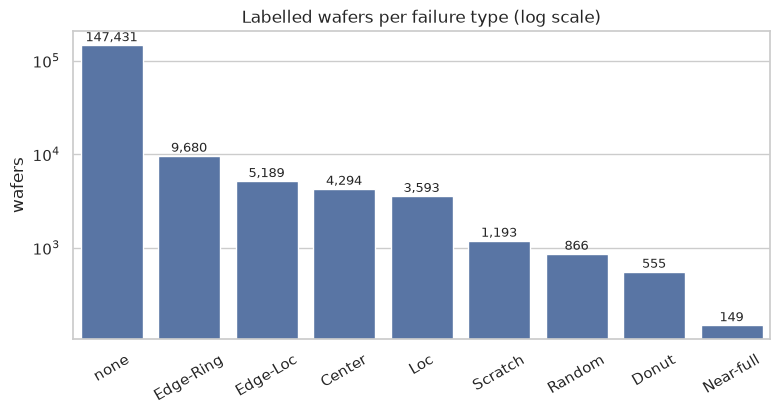

In [4]:
counts = df["failureType"].value_counts().reindex(CLASS_ORDER)
summary = pd.DataFrame({"count": counts, "share_%": (100 * counts / counts.sum()).round(2)})
display(summary)

fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(x=counts.index, y=counts.values, ax=ax, color="#4c72b0")
ax.set_yscale("log")
ax.set(title="Labelled wafers per failure type (log scale)", xlabel="", ylabel="wafers")
for i, v in enumerate(counts.values):
    ax.text(i, v * 1.1, f"{v:,}", ha="center", fontsize=9)
plt.xticks(rotation=30)
savefig("class_distribution"); plt.show()

**Finding:** 85% of labelled wafers are `none`; the rarest class (`Near-full`, 149) is ~1,000× smaller.

**Modelling consequence:**
- Accuracy is misleading (always predicting `none` scores ~85%) → use **macro-F1** and **per-class recall**.
- Use **stratified** splits and **class weights** (and/or downsample `none` in training only).

## Insight 2 — Each failure type has a distinct spatial signature

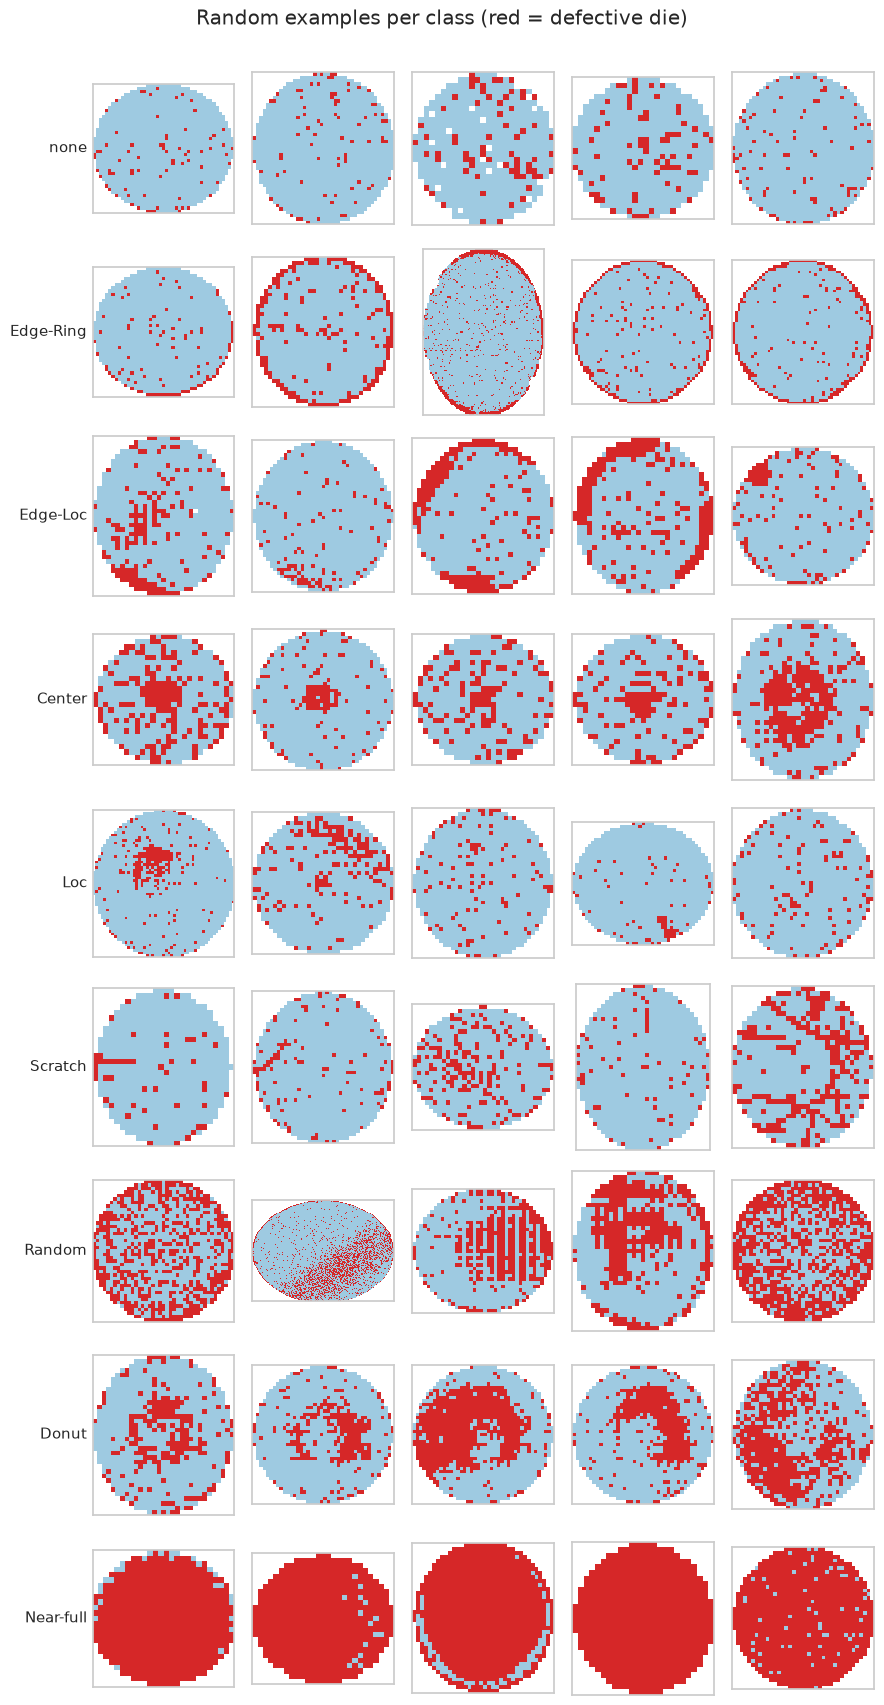

In [5]:
rng = np.random.default_rng(42)
n_examples = 5
fig, axes = plt.subplots(len(CLASS_ORDER), n_examples, figsize=(n_examples * 1.8, len(CLASS_ORDER) * 1.9))
for r, cls in enumerate(CLASS_ORDER):
    idx = rng.choice(df.index[df["failureType"] == cls], n_examples, replace=False)
    for c, i in enumerate(idx):
        ax = axes[r, c]
        ax.imshow(df.at[i, "waferMap"], cmap=WAFER_CMAP, vmin=0, vmax=2, interpolation="nearest")
        ax.set_xticks([]); ax.set_yticks([])
        if c == 0:
            ax.set_ylabel(cls, rotation=0, ha="right", va="center", fontsize=11)
fig.suptitle("Random examples per class (red = defective die)", y=1.0)
plt.tight_layout()
savefig("examples_per_class"); plt.show()

**Finding:** classes are defined by *where* defects are (centre, ring, edge, line) rather than *how many*.
Some pairs look alike (Loc vs Edge-Loc, Center vs Donut) and are likely confusion points.

**Modelling consequence:** engineer **spatial features** — defect density per region (centre/rings/edge),
Radon-transform features for lines and rings, and geometry of the largest defect cluster.

**Label noise:** some examples look mislabelled (e.g. an `Edge-Ring` wafer with no visible ring, a `Scratch` that looks random).
Labels were assigned by human engineers, so the model's ceiling is limited by label quality. Revisit this in error analysis.

## Insight 3 — Wafer maps come in hundreds of different sizes

346 distinct map shapes
         n_rows    n_cols     n_die
count  172950.0  172950.0  172950.0
mean       35.2      34.8    1042.2
std        11.1      11.9    1032.6
min        15.0       3.0       3.0
25%        27.0      27.0     533.0
50%        33.0      33.0     776.0
75%        41.0      40.0    1250.0
max       212.0     204.0   22372.0


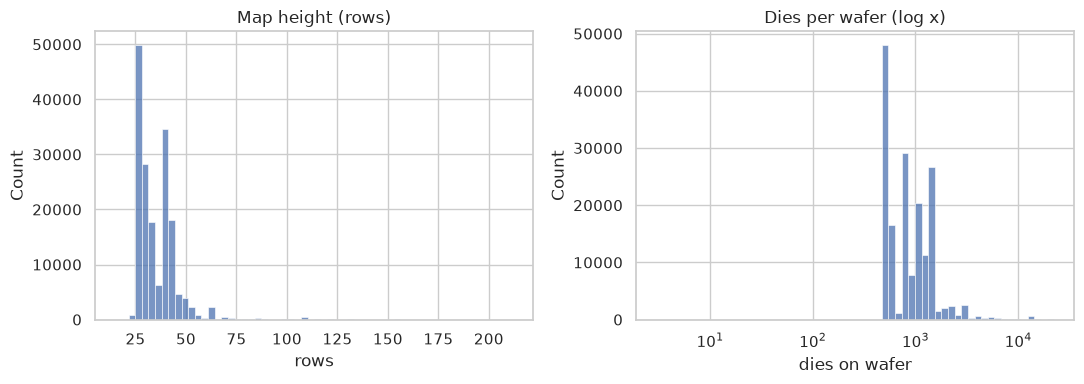

In [6]:
n_shapes = df.groupby(["n_rows", "n_cols"]).ngroups
print(f"{n_shapes} distinct map shapes")
print(df[["n_rows", "n_cols", "n_die"]].describe().round(1))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df["n_rows"], bins=60, ax=axes[0])
axes[0].set(title="Map height (rows)", xlabel="rows")
sns.histplot(df["n_die"], bins=60, ax=axes[1], log_scale=True)
axes[1].set(title="Dies per wafer (log x)", xlabel="dies on wafer")
plt.tight_layout()
savefig("map_sizes"); plt.show()

In [7]:
# Extremely small maps are likely data-quality issues — inspect them
tiny = df[df["n_die"] < 100]
print(f"{len(tiny):,} wafers with < 100 dies")
tiny["failureType"].value_counts()

4 wafers with < 100 dies


failureType
none    4
Name: count, dtype: int64

**Finding:** map dimensions range from a few to 200+ dies across; die count varies by orders of magnitude.

**Modelling consequence:** models need a **fixed-length input** → use size-independent features
(proportions per region, normalised Radon profiles) or resize maps (e.g. 64×64) for a CNN.
Very small maps are outlier candidates to inspect / filter.

**Note:** `dieSize` is exactly the number of dies on the wafer (equal for 100% of rows), so it is a size feature, not die *area*.

## Insight 4 — Wafers in the same lot share defect types (leakage risk)

wafers per lot: {'count': 10762.0, 'mean': 16.1, 'std': 10.6, 'min': 1.0, '25%': 2.0, '50%': 23.0, '75%': 25.0, 'max': 25.0}


Lots containing defects: 8,047
Avg distinct defect types per lot: 1.28
Avg share of a lot's defects that are its dominant type: 90%


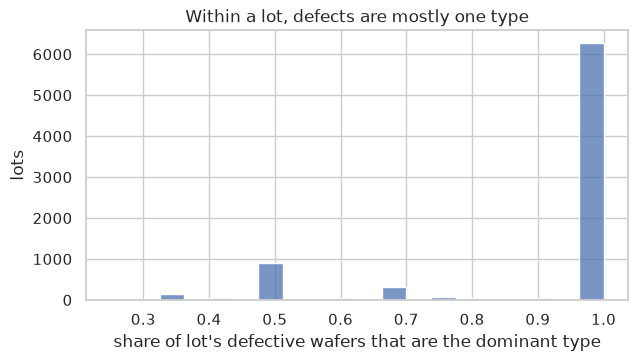

In [8]:
lot_size = df.groupby("lotName").size()
print("wafers per lot:", lot_size.describe().round(1).to_dict())

defects = df[df["is_defect"]]
dominant_share = defects.groupby("lotName")["failureType"].agg(
    lambda s: s.value_counts(normalize=True).iloc[0])
types_per_lot = defects.groupby("lotName")["failureType"].nunique()
print(f"Lots containing defects: {defects['lotName'].nunique():,}")
print(f"Avg distinct defect types per lot: {types_per_lot.mean():.2f}")
print(f"Avg share of a lot's defects that are its dominant type: {dominant_share.mean():.0%}")

fig, ax = plt.subplots(figsize=(7, 3.5))
sns.histplot(dominant_share, bins=20, ax=ax)
ax.set(title="Within a lot, defects are mostly one type",
       xlabel="share of lot's defective wafers that are the dominant type", ylabel="lots")
savefig("lot_dominant_type"); plt.show()

**Finding:** within a lot, ~90% of defective wafers share one failure type — wafers from the same lot
went through the same tools and are strongly correlated.

**Modelling consequence:** a random row split would put near-duplicate wafers in both train and test and
**inflate scores**. Split and cross-validate **by lot** (`GroupShuffleSplit` / `StratifiedGroupKFold`
with `groups=lotName`).

## Insight 5 — The dataset's own train/test label is badly skewed

trainTestLabel,Test,Training,test_share_%
failureType,,,
none,110701,36730,75.1
Edge-Ring,1126,8554,11.6
Edge-Loc,2772,2417,53.4
Center,832,3462,19.4
Loc,1973,1620,54.9
Scratch,693,500,58.1
Random,257,609,29.7
Donut,146,409,26.3
Near-full,95,54,63.8


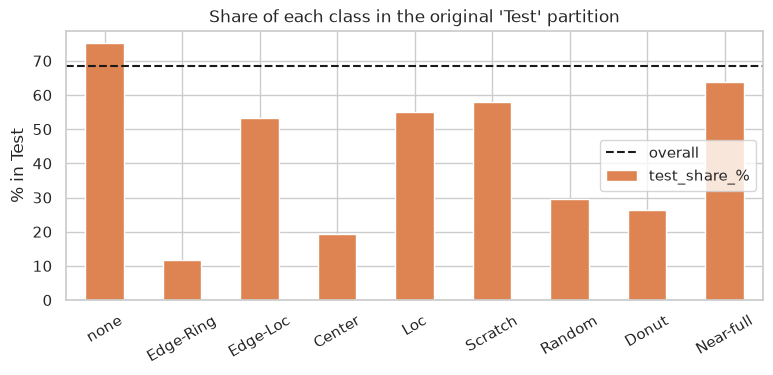

In [9]:
ct = pd.crosstab(df["failureType"], df["trainTestLabel"]).reindex(CLASS_ORDER)
ct["test_share_%"] = (100 * ct["Test"] / ct.sum(axis=1)).round(1)
display(ct)

ax = ct["test_share_%"].plot.bar(figsize=(9, 3.5), color="#dd8452")
ax.axhline(100 * (df["trainTestLabel"] == "Test").mean(), ls="--", c="k", label="overall")
ax.set(title="Share of each class in the original 'Test' partition", ylabel="% in Test", xlabel="")
ax.legend(); plt.xticks(rotation=30)
savefig("original_split_skew"); plt.show()

**Finding:** the supplied `trainTestLabel` is not stratified — e.g. most `Edge-Ring` wafers are in Training
but most `none`, `Loc`, `Edge-Loc` and `Near-full` wafers are in Test.

**Modelling consequence:** ignore it and build our **own stratified, lot-grouped split**.

## Insight 6 — Defect density alone separates some classes, but not all

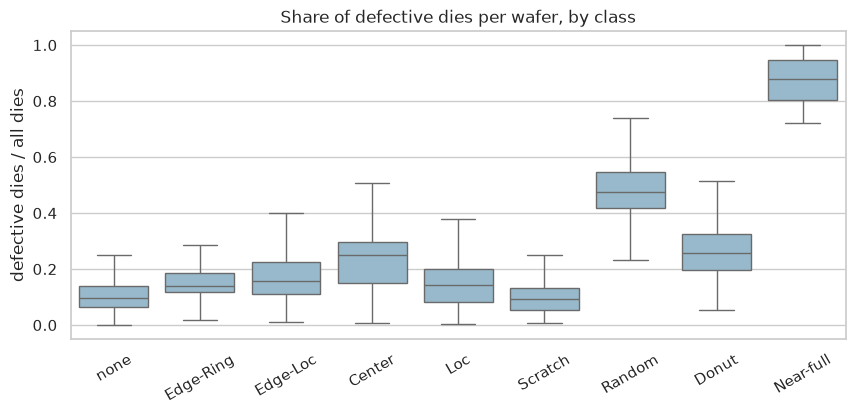

failureType
none         0.098
Edge-Ring    0.140
Edge-Loc     0.156
Center       0.250
Loc          0.142
Scratch      0.092
Random       0.477
Donut        0.258
Near-full    0.878
Name: pct_bad, dtype: float64

In [10]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(data=df, x="failureType", y="pct_bad", order=CLASS_ORDER, ax=ax,
            showfliers=False, color="#8fbcd4")
ax.set(title="Share of defective dies per wafer, by class", xlabel="", ylabel="defective dies / all dies")
plt.xticks(rotation=30)
savefig("defect_density_by_class"); plt.show()
df.groupby("failureType")["pct_bad"].median().reindex(CLASS_ORDER).round(3)

**Finding:** `Near-full` and `Random` have far higher defect density, but `none`, `Scratch`, `Loc`, `Edge-Loc`
and `Edge-Ring` overlap heavily — density alone can't separate them.

**Modelling consequence:** include overall density as a feature, but rely on **spatial** features
(Insight 2) to separate the overlapping classes. A density-only model is a useful simple baseline.

## Summary — findings → modelling decisions

| # | Finding | Decision |
|---|---|---|
| 1 | 85% `none`, rarest class 149 wafers | Macro-F1 + per-class recall; stratify; class weights |
| 2 | Classes defined by spatial pattern | Region-density, Radon and cluster-geometry features |
| 3 | 346 different map shapes | Size-independent features (or resize for CNN); check tiny maps |
| 4 | Lots share defect types | Split / CV grouped by `lotName` |
| 5 | Supplied train/test split is skewed | Build our own stratified, lot-grouped split |
| 6 | Density separates only some classes | Keep density as a feature; spatial features do the rest |

Figures for the slides are saved in `reports/figures/`.